In [70]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import torch.optim as optim
import matplotlib.pyplot as plt

torch.manual_seed(42)                                    # PyTorch 랜덤 고정 (가중치 초기값, 데이터 섞기)
np.random.seed(42)                                       # 넘파이 랜덤 고정

In [71]:
# 데이터 로드
data = pd.read_csv("abalone.csv")
data = data.drop("id", axis=1)                           # id는 단순 번호 → 제거

In [72]:
# 범주형 인코딩 (원-핫)
data = pd.get_dummies(data, columns=['Sex'], dtype=float)  # Sex → Sex_F, Sex_I, Sex_M 컬럼(0/1)으로 분리
print(data.head())                                         # 변환 결과 확인

   Length  Diameter  Height  Whole_weight  Shucked_weight  Viscera_weight  \
0   0.455     0.365   0.095        0.5140          0.2245          0.1010   
1   0.350     0.265   0.090        0.2255          0.0995          0.0485   
2   0.530     0.420   0.135        0.6770          0.2565          0.1415   
3   0.440     0.365   0.125        0.5160          0.2155          0.1140   
4   0.330     0.255   0.080        0.2050          0.0895          0.0395   

   Shell_weight  Rings  Sex_F  Sex_I  Sex_M  
0         0.150     15    0.0    0.0    1.0  
1         0.070      7    0.0    0.0    1.0  
2         0.210      9    1.0    0.0    0.0  
3         0.155     10    0.0    0.0    1.0  
4         0.055      7    0.0    1.0    0.0  


In [73]:
# 입력과 타겟 분리
X = data.drop('Rings', axis=1).values                    # 입력: 특성 8개
y = data['Rings'].values.astype(np.float32)              # 타겟: 나이테 수 (연속값 → 회귀)

In [74]:
# 정규화
scaler = StandardScaler()                                # 평균 0, 표준편차 1로 변환
X = scaler.fit_transform(X)                              # 전체 X 기준으로 정규화

In [75]:
# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  # 8:2 분리, 분할 고정

In [76]:
# 텐서 변환 및 TensorDataset으로 래핑
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)            # 넘파이 → 파이토치 텐서
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1) # (n,) → (n,1): 모델 출력 모양과 맞춤
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)          # 입력과 정답을 한 쌍으로 묶기
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)  # 32개씩, 매 epoch 섞어서 공급
test_loader = DataLoader(test_dataset, batch_size=32)                  # 테스트는 섞을 필요 없음

In [77]:
# 회귀 모델 정의
class RegressionModel(nn.Module):                        # nn.Module을 상속해서 모델 만들기
    def __init__(self):
        super(RegressionModel, self).__init__()          # 부모 클래스 초기화
        self.model = nn.Sequential(
            nn.Linear(10, 64),                            # 입력 8개 → 은닉층 64개
            nn.ReLU(),                                   # 활성화 함수
            nn.Linear(64, 32),                           # 은닉층 64 → 32
            nn.ReLU(),
            nn.Linear(32, 1)                             # 출력 1개 (나이테 수), 활성화 없음 → 회귀
        )

    def forward(self, x):                                # 데이터가 모델을 통과하는 순서
        return self.model(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # GPU 있으면 GPU, 없으면 CPU
model = RegressionModel().to(device)                     # 모델을 장치로 이동
criterion = nn.MSELoss()                                 # 손실 함수: 평균제곱오차
optimizer = optim.Adam(model.parameters(), lr=0.001)     # 옵티마이저: Adam, 학습률 0.001
print(model)

RegressionModel(
  (model): Sequential(
    (0): Linear(in_features=10, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [78]:
# 학습 루프
model.train()
loss_history = []

for epoch in range(30):
    total_loss = 0
    for X_batch, y_batch in train_loader:                # 32개씩 꺼내기
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)  # 데이터를 장치로 이동
        optimizer.zero_grad()                            # ① 이전 기울기 초기화
        output = model(X_batch)                          # ② 예측 (순전파)
        loss = criterion(output, y_batch)                # ③ 손실 계산
        loss.backward()                                  # ④ 기울기 계산 (역전파)
        optimizer.step()                                 # ⑤ 가중치 업데이트
        total_loss += loss.item()                        # 배치 손실 누적
    avg_loss = total_loss / len(train_loader)            # epoch 평균 손실
    loss_history.append(avg_loss)
    print(f"Epoch {epoch+1}, Loss: {avg_loss:.4f}")

Epoch 1, Loss: 63.0233
Epoch 2, Loss: 13.1543
Epoch 3, Loss: 7.4322
Epoch 4, Loss: 6.2522
Epoch 5, Loss: 5.7669
Epoch 6, Loss: 5.5134
Epoch 7, Loss: 5.2625
Epoch 8, Loss: 5.1415
Epoch 9, Loss: 4.9958
Epoch 10, Loss: 4.9571
Epoch 11, Loss: 4.8670
Epoch 12, Loss: 4.7533
Epoch 13, Loss: 4.7401
Epoch 14, Loss: 4.7710
Epoch 15, Loss: 4.6249
Epoch 16, Loss: 4.6132
Epoch 17, Loss: 4.6086
Epoch 18, Loss: 4.5736
Epoch 19, Loss: 4.5274
Epoch 20, Loss: 4.5685
Epoch 21, Loss: 4.5004
Epoch 22, Loss: 4.4580
Epoch 23, Loss: 4.4686
Epoch 24, Loss: 4.4218
Epoch 25, Loss: 4.4284
Epoch 26, Loss: 4.4355
Epoch 27, Loss: 4.4173
Epoch 28, Loss: 4.4045
Epoch 29, Loss: 4.3984
Epoch 30, Loss: 4.3636


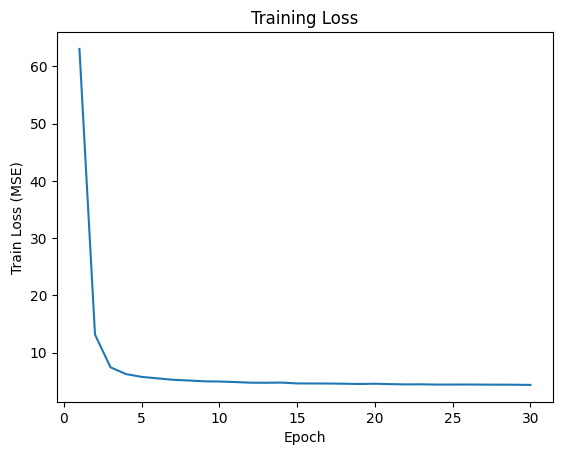

In [79]:
# 학습 과정 시각화
plt.plot(range(1, 31), loss_history)                     # epoch별 손실 변화
plt.xlabel('Epoch')
plt.ylabel('Train Loss (MSE)')
plt.title('Training Loss')
plt.show()

In [80]:
# 평가
model.eval()                                             # 평가 모드
preds, actuals = [], []
with torch.no_grad():                                    # 기울기 계산 안 함 (평가만, 속도↑ 메모리↓)
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        outputs = model(X_batch).cpu().numpy()           # 예측 → CPU로 옮겨 넘파이로 변환
        preds.extend(outputs.flatten())                  # 예측값 저장
        actuals.extend(y_batch.numpy().flatten())        # 실제값 저장

preds, actuals = np.array(preds), np.array(actuals)

mse = mean_squared_error(actuals, preds)                 # 평균제곱오차
mae = mean_absolute_error(actuals, preds)                # 평균절대오차: 평균 몇 개 차이 나는지
r2 = r2_score(actuals, preds)                            # 결정계수: 1에 가까울수록 잘 맞춤
print(f"Test MSE: {mse:.4f}")
print(f"Test MAE: {mae:.4f}")
print(f"Test R² : {r2:.4f}")

Test MSE: 4.6189
Test MAE: 1.5220
Test R² : 0.5733


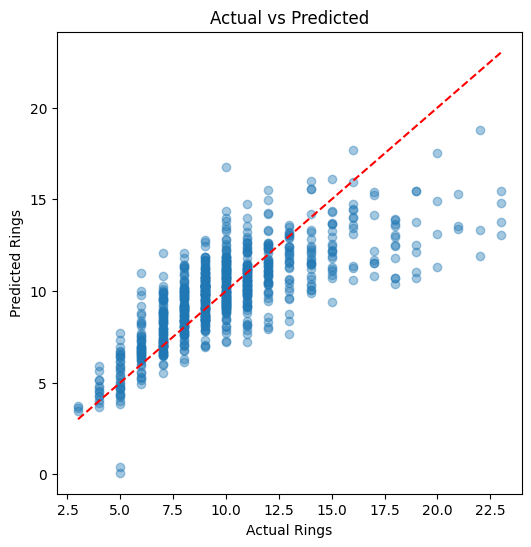

    실제값   예측값   오차
0   9.0  11.8 -2.8
1   8.0  10.2 -2.2
2  16.0  14.4  1.6
3   9.0  11.0 -2.0
4  14.0  12.1  1.9
5  11.0  10.5  0.5
6   7.0   9.5 -2.5
7   6.0   8.8 -2.8
8   7.0   6.9  0.1
9  10.0  10.2 -0.2


In [81]:
# 실제값 vs 예측값 비교
plt.figure(figsize=(6, 6))
plt.scatter(actuals, preds, alpha=0.4)                   # 점 하나 = 전복 1마리
plt.plot([actuals.min(), actuals.max()],
         [actuals.min(), actuals.max()], 'r--')          # 빨간 대각선 = 완벽한 예측
plt.xlabel('Actual Rings')
plt.ylabel('Predicted Rings')
plt.title('Actual vs Predicted')
plt.show()

result = pd.DataFrame({'실제값': actuals[:10],
                       '예측값': preds[:10].round(1),
                       '오차': (actuals[:10] - preds[:10]).round(1)})  # 앞 10개 비교
print(result)

## 실습 정리: Abalone 회귀

### 실습 목표
전복의 크기, 무게, 성별 정보로 **나이테 수(Rings)를 예측**하는 딥러닝 회귀 모델

### 실험 조건
- 데이터: abalone.csv (4,177개, 입력 특성 10개 → 정답 Rings)
- 전처리: `id` 제거, Sex를 원-핫 인코딩(Sex_F, Sex_I, Sex_M), `StandardScaler`로 정규화
- 분할: `train_test_split(test_size=0.2, random_state=42)` → 학습 3,341개 / 테스트 836개
- 랜덤 고정: `torch.manual_seed(42)`

### 모델 구성
| 항목 | 설정 |
|---|---|
| 구조 | `Linear(10, 64) → ReLU → Linear(64, 32) → ReLU → Linear(32, 1)` |
| 출력층 | 뉴런 1개, 활성화 함수 없음 (연속된 숫자 예측) |
| 손실 함수 | `MSELoss` |
| 옵티마이저 | Adam (lr=0.001) |
| 학습 | epochs 30, batch_size 32 |

### 결과
| 지표 | 값 | 의미 |
|---|---|---|
| MSE | 4.5776 | 오차 제곱의 평균, 학습에 사용한 손실 함수 |
| MAE | 1.5202 | 나이테 수를 평균 약 1.5개 정도 틀림 |
| R² | 0.5771 | 나이테 수 변화의 약 58%를 설명함 |

### PyTorch 학습 과정
1. `optimizer.zero_grad()`: 이전 기울기 초기화
2. `model(X_batch)`: 예측 (순전파)
3. `criterion(output, y_batch)`: 손실 계산
4. `loss.backward()`: 기울기 계산 (역전파)
5. `optimizer.step()`: 가중치 업데이트

### 느낀 점
- 회귀는 정답이 연속된 숫자라서, 맞았는지 틀렸는지가 아니라 **얼마나 가깝게 예측했는지**로 평가한다.
- MSE는 단위가 제곱이라 해석하기 어려워서, MAE로 실제 오차 크기를 확인하고 R²로 모델의 설명력을 함께 확인했다.
- 실제값 vs 예측값 그래프를 보면 나이테가 많은 전복일수록 오차가 커지는 경향이 있다. 크기와 무게만으로는 나이를 정확히 알기 어렵다는 한계를 확인했다.
- Sex는 순서가 없는 범주라서 `LabelEncoder`(0, 1, 2) 대신 원-핫 인코딩을 사용했다. 숫자 크기에 의미가 생기는 문제를 막을 수 있다.
- MSE가 MAE²보다 크게 나온 것은 일부 데이터에서 크게 틀렸기 때문이다. 주로 나이테가 많은 전복에서 오차가 컸는데, 다 자란 전복은 크기·무게가 더 이상 늘지 않아 입력 특성만으로 나이를 구분하기 어렵기 때문이다. 이는 모델의 문제라기보다 데이터의 한계이다.
